# Nhiệm vụ 3: Đánh giá Chất lượng Dữ liệu cho Bài toán Hồi quy (Regression Readiness Audit)

**Thành viên thực hiện**: TV3 (Exploratory Data Analysis - EDA)  
**Mã học phần**: IT4930 - Khoa học Dữ liệu & Trí tuệ Kinh doanh  
**Tập dữ liệu**: `data/processed/products_processed.jsonl` ($N = 10.316$ listings)  
**Tài liệu quy chuẩn**: [docs/tv3/tv3.md](file:///d:/NMKHDL/it4930-ecommerce-data-intelligence/docs/tv3/tv3.md) & [docs/feature_contracts_tv3_tv8.md](file:///d:/NMKHDL/it4930-ecommerce-data-intelligence/docs/feature_contracts_tv3_tv8.md)

---
### Mục tiêu nghiên cứu:
1. **Nhận diện Ngoại lai (Outliers) & Dữ liệu biên**: Rà soát 1.768 bản ghi không hợp lệ (`is_price_missing == True`, `price_vnd <= 0`), lập bảng phân vị biên P0.1 - P99.9 và phân loại các nhóm ngoại lai cực biên (< 500k và > 100M).
2. **Hiện tượng Đa cộng tuyến (Multicollinearity)**: Đo lường tương quan chéo giữa các biến độc lập số và tính toán chỉ số phóng đại phương sai (**Variance Inflation Factor - VIF**), đưa ra cảnh báo cho mô hình tuyến tính OLS/Ridge/Lasso.
3. **Phòng chống Rò rỉ Dữ liệu (Data Leakage Risks Audit)**: Thiết lập ma trận rà soát Blacklist vs Whitelist (loại bỏ triệt để `discount_rate`, `original_price_vnd`, `listing_record_id`, `crawl_time`).
4. **Tác động của Trạng thái Tồn kho (`availability_status`)**: Đo lường hiện tượng lệch giá (**Price Drift**) của các sản phẩm `out_of_stock` (hàng ngừng kinh doanh EOL mang giá niêm yết cũ).
5. **Tuyên bố Khoa học Bắt buộc**: Các kết quả là bằng chứng khám phá thực nghiệm (*exploratory associations*), không cấu thành suy diễn nhân quả (*causal inference*).

In [1]:
import os
import sys
from pathlib import Path

# Tự động định vị REPO_ROOT (chứa data/processed) và đưa working directory về root
curr = Path.cwd().resolve()
while curr != curr.parent:
    if (curr / "data" / "processed" / "products_processed.jsonl").exists():
        os.chdir(curr)
        break
    curr = curr.parent

if "src/eda/scripts" not in sys.path:
    sys.path.insert(0, "src/eda/scripts")

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Thiết lập import module EDA nội bộ

from eda_stats import (
    load_processed_products,
    audit_price_outliers_and_boundaries,
    compute_multicollinearity_and_vif,
    audit_data_leakage_risks,
    analyze_availability_status_impact
)
from eda_viz import (
    set_plotting_theme,
    plot_price_outliers_and_boundaries,
    plot_multicollinearity_and_vif,
    plot_availability_price_comparison
)

set_plotting_theme()
print("[*] Hệ thống thư viện EDA Task 3 đã sẵn sàng!")


[*] Hệ thống thư viện EDA Task 3 đã sẵn sàng!


In [2]:
# Tải dữ liệu chuẩn hóa
data_path = "data/processed/products_processed.jsonl"
df = load_processed_products(data_path)
print(f"[+] Tổng số bản ghi quan sát: {len(df):,}")


[+] Tổng số bản ghi quan sát: 10,316


## 1. Nhận diện Outliers & Dữ liệu biên (Task 3.1)
Kiểm toán các bản ghi thiếu giá, giá âm, phân vị cực biên và các trường hợp ngoại lai cực đoan.

In [3]:
invalid_summary, boundary_df, outlier_summary = audit_price_outliers_and_boundaries(df)

print("=== BẢNG 3.1A: KIỂM TOÁN CÁC BẢN GHI GIÁ THIẾU VÀ KHÔNG HỢP LỆ ===")
display(invalid_summary)

print("\n=== BẢNG 3.1B: BẢNG PHÂN VỊ CỰC BIÊN VÀ TUKEY FENCES CỦA GIÁ BÁN ===")
display(boundary_df)

print("\n=== BẢNG 3.1C: NHẬN DIỆN VÀ ĐÁNH GIÁ CÁC NHÓM NGOẠI LAI CỰC BIÊN ===")
display(outlier_summary)


=== BẢNG 3.1A: KIỂM TOÁN CÁC BẢN GHI GIÁ THIẾU VÀ KHÔNG HỢP LỆ ===


,Tiêu chí kiểm tra,Số lượng bản ghi,Tỷ lệ trên tổng (%),Ghi chú / Hành động TV5
0,is_price_missing == True,1752,16.98,Bắt buộc loại bỏ khỏi tập huấn luyện hồi quy (...
1,price_vnd <= 0,1752,16.98,Giá bằng 0 hoặc âm; trùng khớp với is_price_mi...
2,price_vnd là NaN / Null,16,0.16,16 bản ghi thiếu giá hoàn toàn từ file thô
3,Tổng số bản ghi giá KHÔNG HỢP LỆ,1768,17.14,Loại bỏ triệt để 1.768 bản ghi này (còn 8.548 ...



=== BẢNG 3.1B: BẢNG PHÂN VỊ CỰC BIÊN VÀ TUKEY FENCES CỦA GIÁ BÁN ===


,Phân khúc,N hợp lệ,Min,P0.1,P1,P5,Q1 (25%),Trung vị,Q3 (75%),P95,P99,P99.9,Max,IQR,Tukey Upper (1.5 IQR),Extreme Upper (3.0 IQR)
0,Toàn bộ dữ liệu,8548,0.004,0.180,0.49,2.39,7.89,19.49,29.99,61.49,101.99,184.49,485.00,22.1,63.14,96.29
1,Laptop,4222,1.690,2.066,8.99,12.49,19.29,26.84,38.99,73.99,119.39,194.19,269.99,19.7,68.54,98.09
2,Smartphone,4326,0.004,0.170,0.39,0.85,3.99,7.99,20.09,41.99,70.32,103.99,485.00,16.1,44.24,68.39



=== BẢNG 3.1C: NHẬN DIỆN VÀ ĐÁNH GIÁ CÁC NHÓM NGOẠI LAI CỰC BIÊN ===


,Nhóm giá ngoại lai,Số lượng (N),Tỷ lệ trên N hợp lệ (%),Đặc điểm sản phẩm,Khuyến nghị TV5
0,Giá cực thấp (< 500.000 VNĐ),97,1.13,"Điện thoại 'cục gạch' (Itel, Masstel, Energize...",Lọc bỏ nếu TV5 chỉ dự đoán Smartphone cảm ứng;...
1,Giá cực cao (> 100.000.000 VNĐ),87,1.02,"MacBook Pro M3 Max 128GB/8TB (180M), ROG Strix...",Outlier tự nhiên chuẩn xác (True Flagship Outl...


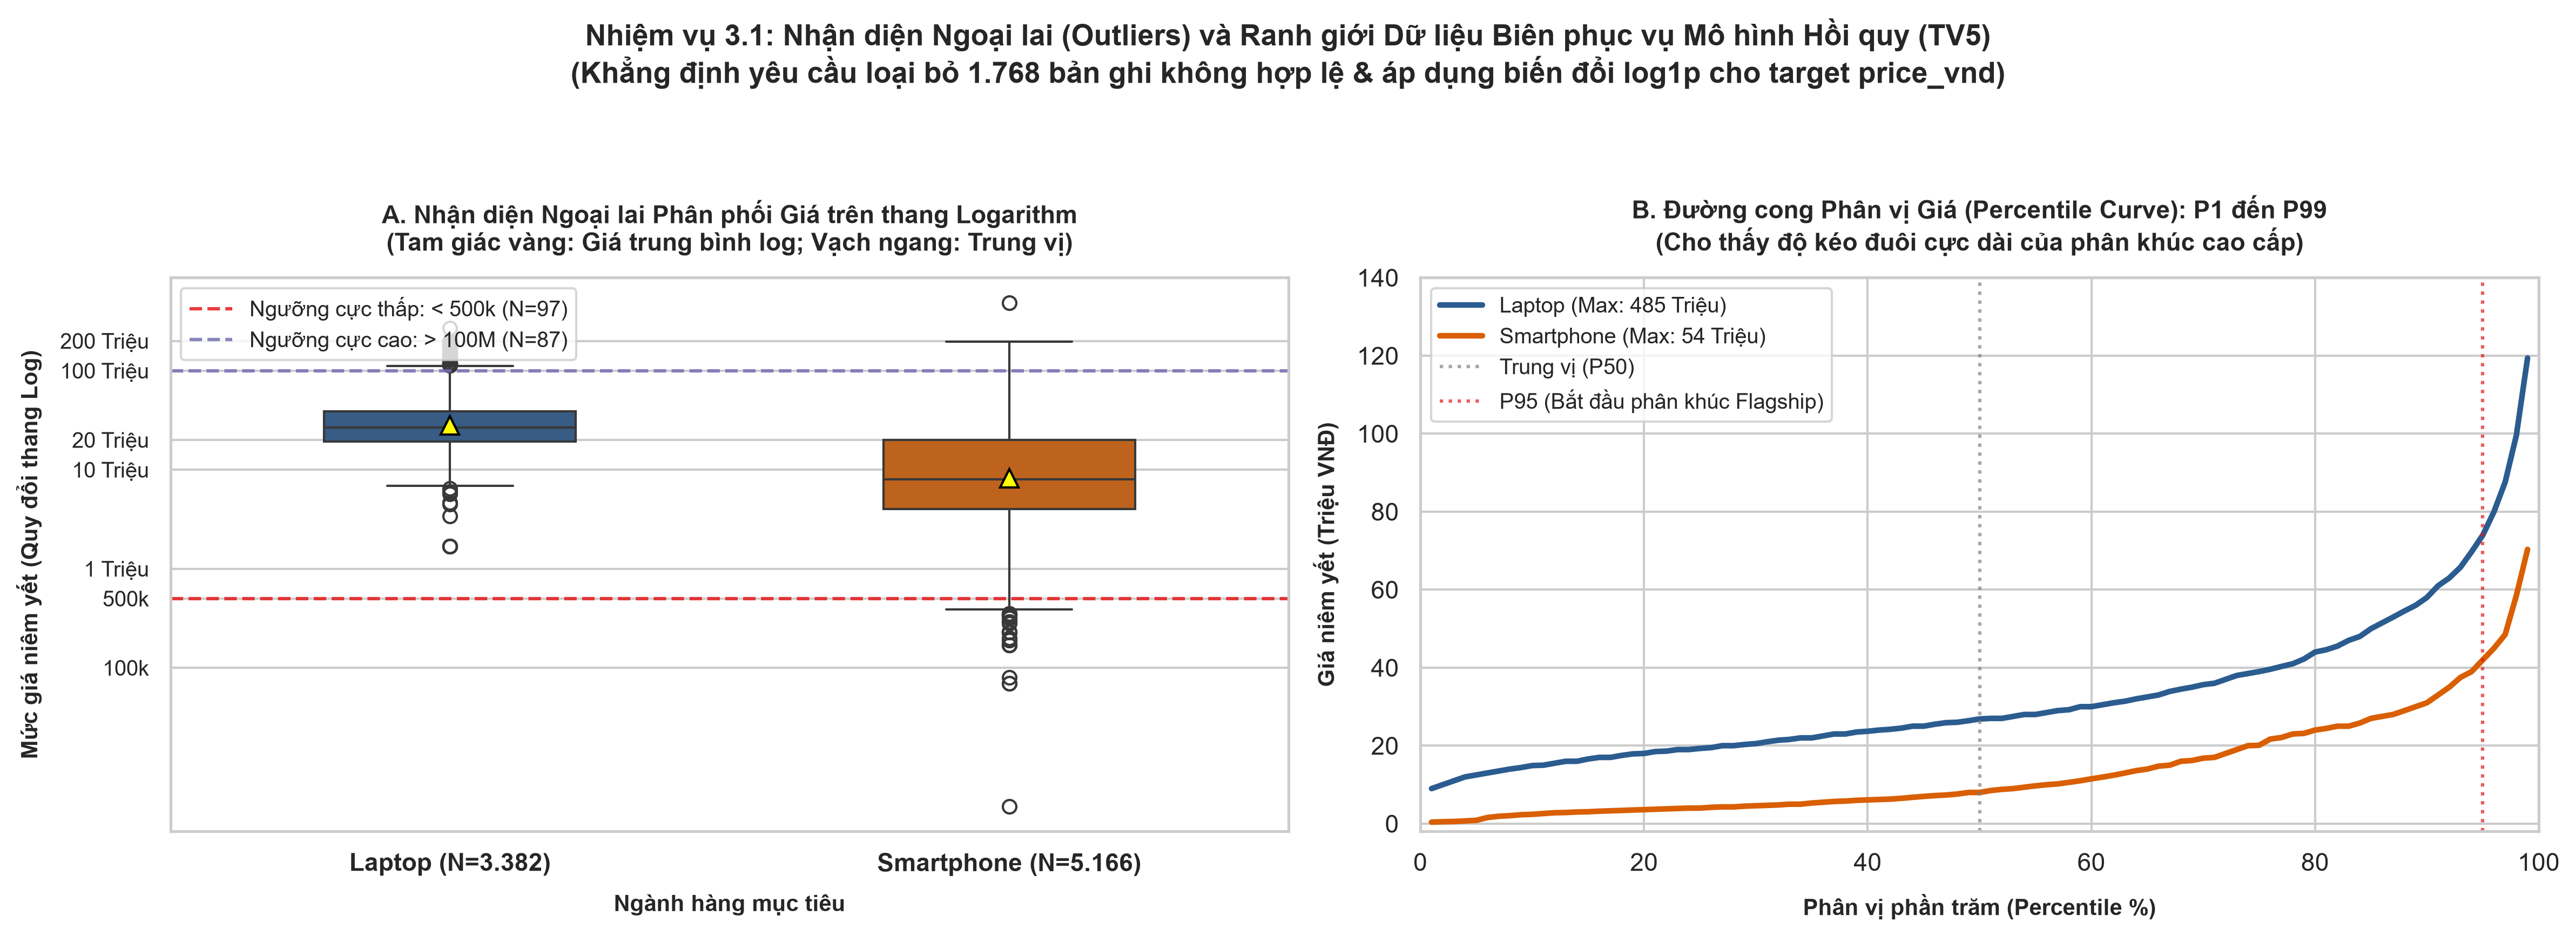

In [4]:
plot_price_outliers_and_boundaries(df, "src/eda/outputs/figures/fig_3_1_price_outliers_and_boundaries.png")
Image("src/eda/outputs/figures/fig_3_1_price_outliers_and_boundaries.png")


## 2. Đo lường Hiện tượng Đa cộng tuyến & Tính toán VIF (Task 3.2)
Phân tích tương quan chéo giữa các biến độc lập và tính hệ số phóng đại phương sai (VIF).

In [5]:
lap_corr, ph_corr, vif_df = compute_multicollinearity_and_vif(df)

print("=== BẢNG 3.2A: MA TRẬN TƯƠNG QUAN CHÉO LAPTOP ===")
display(lap_corr)

print("\n=== BẢNG 3.2B: MA TRẬN TƯƠNG QUAN CHÉO SMARTPHONE ===")
display(ph_corr)

print("\n=== BẢNG 3.2C: CHỈ SỐ VIF (VARIANCE INFLATION FACTOR) ===")
display(vif_df)


=== BẢNG 3.2A: MA TRẬN TƯƠNG QUAN CHÉO LAPTOP ===


,installed_ram_gb,storage_gb,battery_wh,screen_size_inch,charger_watt
installed_ram_gb,1.000,0.234,0.542,-0.017,0.077
storage_gb,0.234,1.000,-0.246,0.267,0.204
battery_wh,0.542,-0.246,1.000,-0.407,0.213
screen_size_inch,-0.017,0.267,-0.407,1.000,0.284
charger_watt,0.077,0.204,0.213,0.284,1.000



=== BẢNG 3.2B: MA TRẬN TƯƠNG QUAN CHÉO SMARTPHONE ===


,installed_ram_gb,storage_gb,battery_mah,charger_watt,screen_size_inch
installed_ram_gb,1.000,0.833,0.181,0.737,0.369
storage_gb,0.833,1.000,0.095,0.624,0.168
battery_mah,0.181,0.095,1.000,0.203,0.193
charger_watt,0.737,0.624,0.203,1.000,0.171
screen_size_inch,0.369,0.168,0.193,0.171,1.000



=== BẢNG 3.2C: CHỈ SỐ VIF (VARIANCE INFLATION FACTOR) ===


,Ngành hàng,Thuộc tính (Feature),VIF Score,Mức độ Đa cộng tuyến,Mô hình ảnh hưởng nặng,Giải pháp khuyến nghị
0,Laptop,installed_ram_gb,2.05,Thấp (An toàn),OLS Linear Regression,Chấp nhận được cho hồi quy tuyến tính; an toàn...
1,Laptop,storage_gb,1.51,Thấp (An toàn),OLS Linear Regression,Chấp nhận được cho hồi quy tuyến tính; an toàn...
2,Laptop,battery_wh,2.82,Trung bình,OLS Linear Regression,Chấp nhận được cho hồi quy tuyến tính; an toàn...
3,Laptop,screen_size_inch,1.62,Thấp (An toàn),OLS Linear Regression,Chấp nhận được cho hồi quy tuyến tính; an toàn...
4,Laptop,charger_watt,1.46,Thấp (An toàn),OLS Linear Regression,Chấp nhận được cho hồi quy tuyến tính; an toàn...
5,Smartphone,installed_ram_gb,5.44,Cao (Cảnh báo),OLS Linear Regression,RAM và ROM tương quan r = 0.83; Cần Ridge L2 R...
6,Smartphone,storage_gb,3.55,Trung bình,OLS Linear Regression,RAM và ROM tương quan r = 0.83; Cần Ridge L2 R...
7,Smartphone,battery_mah,1.08,Thấp (An toàn),OLS Linear Regression,RAM và ROM tương quan r = 0.83; Cần Ridge L2 R...
8,Smartphone,charger_watt,2.29,Thấp (An toàn),OLS Linear Regression,RAM và ROM tương quan r = 0.83; Cần Ridge L2 R...
9,Smartphone,screen_size_inch,1.31,Thấp (An toàn),OLS Linear Regression,RAM và ROM tương quan r = 0.83; Cần Ridge L2 R...


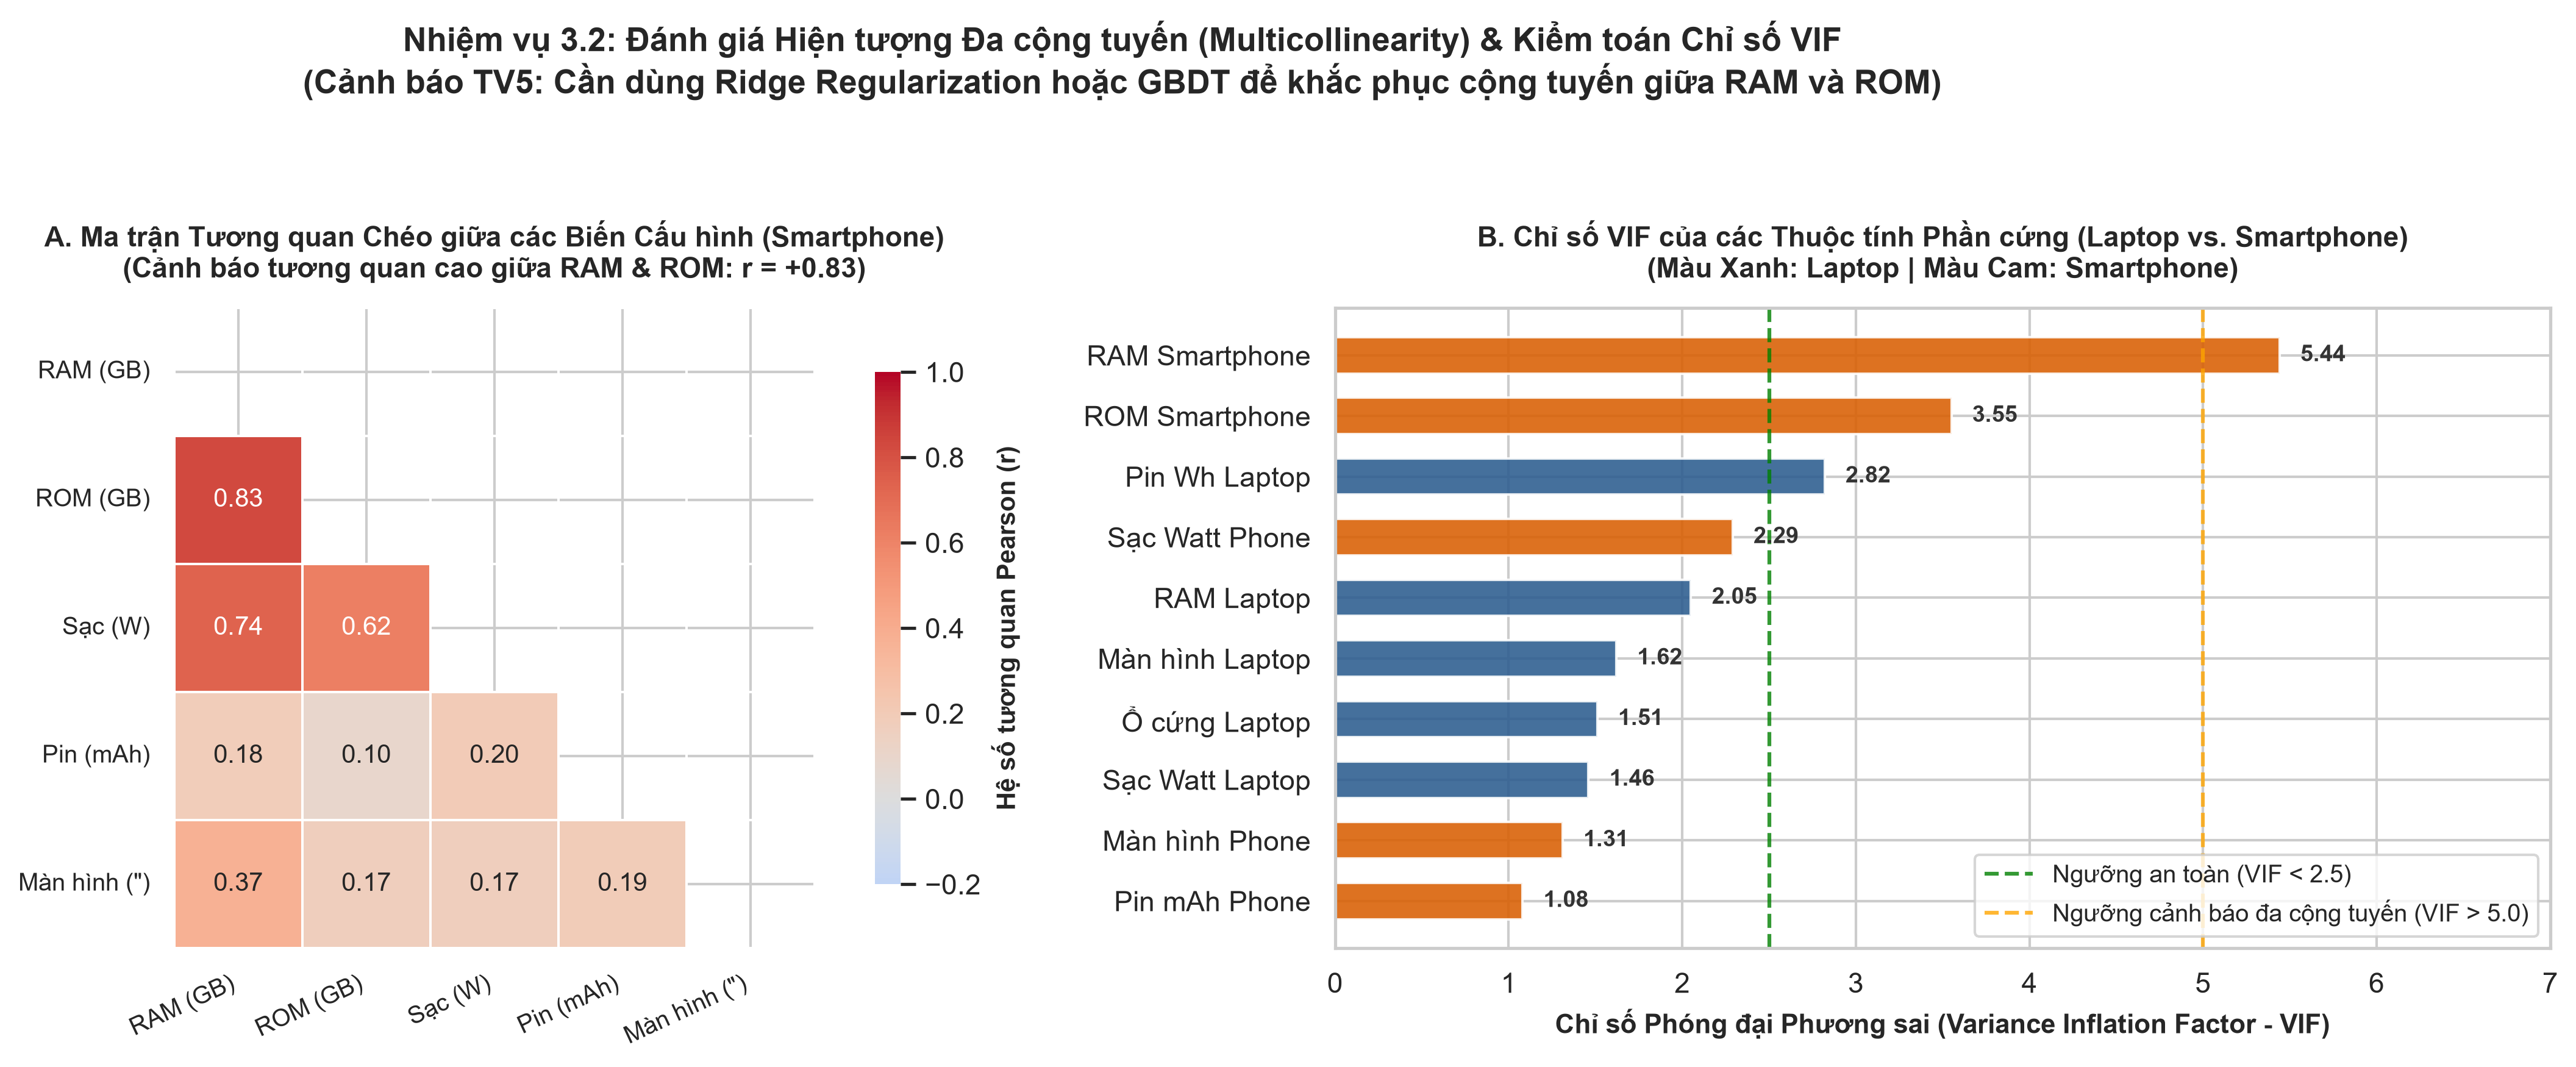

In [6]:
plot_multicollinearity_and_vif(df, "src/eda/outputs/figures/fig_3_2_multicollinearity_and_vif.png")
Image("src/eda/outputs/figures/fig_3_2_multicollinearity_and_vif.png")


## 3. Phòng chống Rò rỉ Dữ liệu (Data Leakage Risks Audit - Task 3.3)
Xác định danh sách Blacklist (loại bỏ hoàn toàn) và Whitelist (candidate features an toàn).

In [7]:
leakage_df = audit_data_leakage_risks()
print("=== BẢNG 3.3: MA TRẬN KIỂM TOÁN RỦI RO RÒ RỈ DỮ LIỆU (TV5) ===")
display(leakage_df)


=== BẢNG 3.3: MA TRẬN KIỂM TOÁN RỦI RO RÒ RỈ DỮ LIỆU (TV5) ===


,Tên trường canonical,Phân loại kiểm toán,Cơ chế rò rỉ / Lý do loại bỏ,Mức độ rủi ro
0,listing_record_id,BLACKLIST (Cấm sử dụng),ID định danh kỹ thuật nội bộ do crawler tự sin...,Nghiêm trọng (Overfitting)
1,source_parent_id,BLACKLIST (Cấm sử dụng),ID nhóm sản phẩm của sàn nguồn; không phải thu...,Nghiêm trọng (Data Leakage)
2,crawl_time,BLACKLIST (Cấm sử dụng),Dấu ấn thời gian cào dữ liệu (Timestamp); mô h...,Trung bình (Temporal Leakage)
3,crawl_batch,BLACKLIST (Cấm sử dụng),Mã đợt cào; trường kỹ thuật nội bộ phục vụ pip...,Thấp (Technical Artifact)
4,discount_rate,BLACKLIST (Cấm sử dụng),RÒ RỈ TRỰC TIẾP TỪ TARGET: discount_rate = 1 -...,TỐI NGUY HIỂM (Direct Target Leakage)
5,original_price_vnd,BLACKLIST (Cấm sử dụng),Giá niêm yết gốc trước giảm giá; tương quan r ...,TỐI NGUY HIỂM (Target Proxy Leakage)
6,is_price_missing,BLACKLIST (Cấm sử dụng),Cờ chỉ báo thiếu target; chỉ dùng để filter dữ...,Nghiêm trọng (Target Indicator)
7,price_vnd,TARGET VARIABLE (Biến mục tiêu),Biến phụ thuộc y cần dự đoán. Khuyến nghị TV5 ...,Biến mục tiêu
8,"category, brand_norm, seller_raw",WHITELIST (Approved Features),Biến danh mục chuẩn hóa hợp lệ; phân loại ngàn...,An toàn (Hợp lệ)
9,"ram, storage, cpu, gpu, battery, charger,...",WHITELIST (Approved Features),Các thuộc tính cấu hình phần cứng vật lý độc l...,An toàn (Hợp lệ)


## 4. Tác động của Trạng thái Tồn kho (`availability_status`) & Price Drift (Task 3.4)
Kiểm định xem các sản phẩm hết hàng (`out_of_stock`) có mang giá niêm yết cũ/lạc hậu hay không.

In [8]:
status_stats, status_test = analyze_availability_status_impact(df)

print("=== BẢNG 3.4A: THỐNG KÊ GIÁ THEO TRẠNG THÁI TỒN KHO ===")
display(status_stats)

print("\n=== BẢNG 3.4B: KIỂM ĐỊNH MANN-WHITNEY U TEST VỀ HIỆN TƯỢNG PRICE DRIFT ===")
display(status_test)


=== BẢNG 3.4A: THỐNG KÊ GIÁ THEO TRẠNG THÁI TỒN KHO ===


,Phân đoạn Ngành hàng,Trạng thái Tồn kho,Số lượng (N),Tỷ lệ nhóm (%),Trung vị (Median),Trung bình (Mean),Độ lệch chuẩn (Std),Q1 (25%),Q3 (75%),IQR
0,Toàn bộ,in_stock,1895,22.2,17.49,23.13,24.92,6.39,30.99,24.60
1,Toàn bộ,out_of_stock,5352,62.6,17.79,21.72,20.88,7.00,27.49,20.49
2,Toàn bộ,unknown,1301,15.2,27.99,30.51,18.84,19.99,38.99,19.00
3,Laptop,in_stock,543,12.9,33.49,40.28,25.38,24.14,48.49,24.35
4,Laptop,out_of_stock,2839,67.2,23.99,30.84,23.13,17.49,35.83,18.34
5,Laptop,unknown,840,19.9,30.54,35.55,16.52,24.59,40.99,16.40
6,Smartphone,in_stock,1352,31.3,9.80,16.24,21.13,4.69,22.99,18.30
7,Smartphone,out_of_stock,2513,58.1,6.49,11.43,11.16,3.69,16.99,13.30
8,Smartphone,unknown,461,10.7,14.29,21.34,19.36,6.69,29.49,22.80



=== BẢNG 3.4B: KIỂM ĐỊNH MANN-WHITNEY U TEST VỀ HIỆN TƯỢNG PRICE DRIFT ===


,Phân đoạn,N in_stock,Median in_stock,N out_of_stock,Median out_of_stock,Chênh lệch Trung vị (Triệu),Mann-Whitney U,p-value,Ý nghĩa thống kê?,Hiện tượng & Khuyến nghị
0,Toàn bộ,1895,17.49,5352,17.79,-0.30M (-1.7%),5123010.0,0.5065,Không,in_stock đắt hơn out_of_stock rõ rệt do hàng h...
1,Laptop,543,33.49,2839,23.99,+9.50M (+39.6%),1036181.0,3.98e-37,Có (p < 0.001),in_stock đắt hơn out_of_stock rõ rệt do hàng h...
2,Smartphone,1352,9.80,2513,6.49,+3.30M (+50.9%),1982360.0,1.02e-17,Có (p < 0.001),in_stock đắt hơn out_of_stock rõ rệt do hàng h...


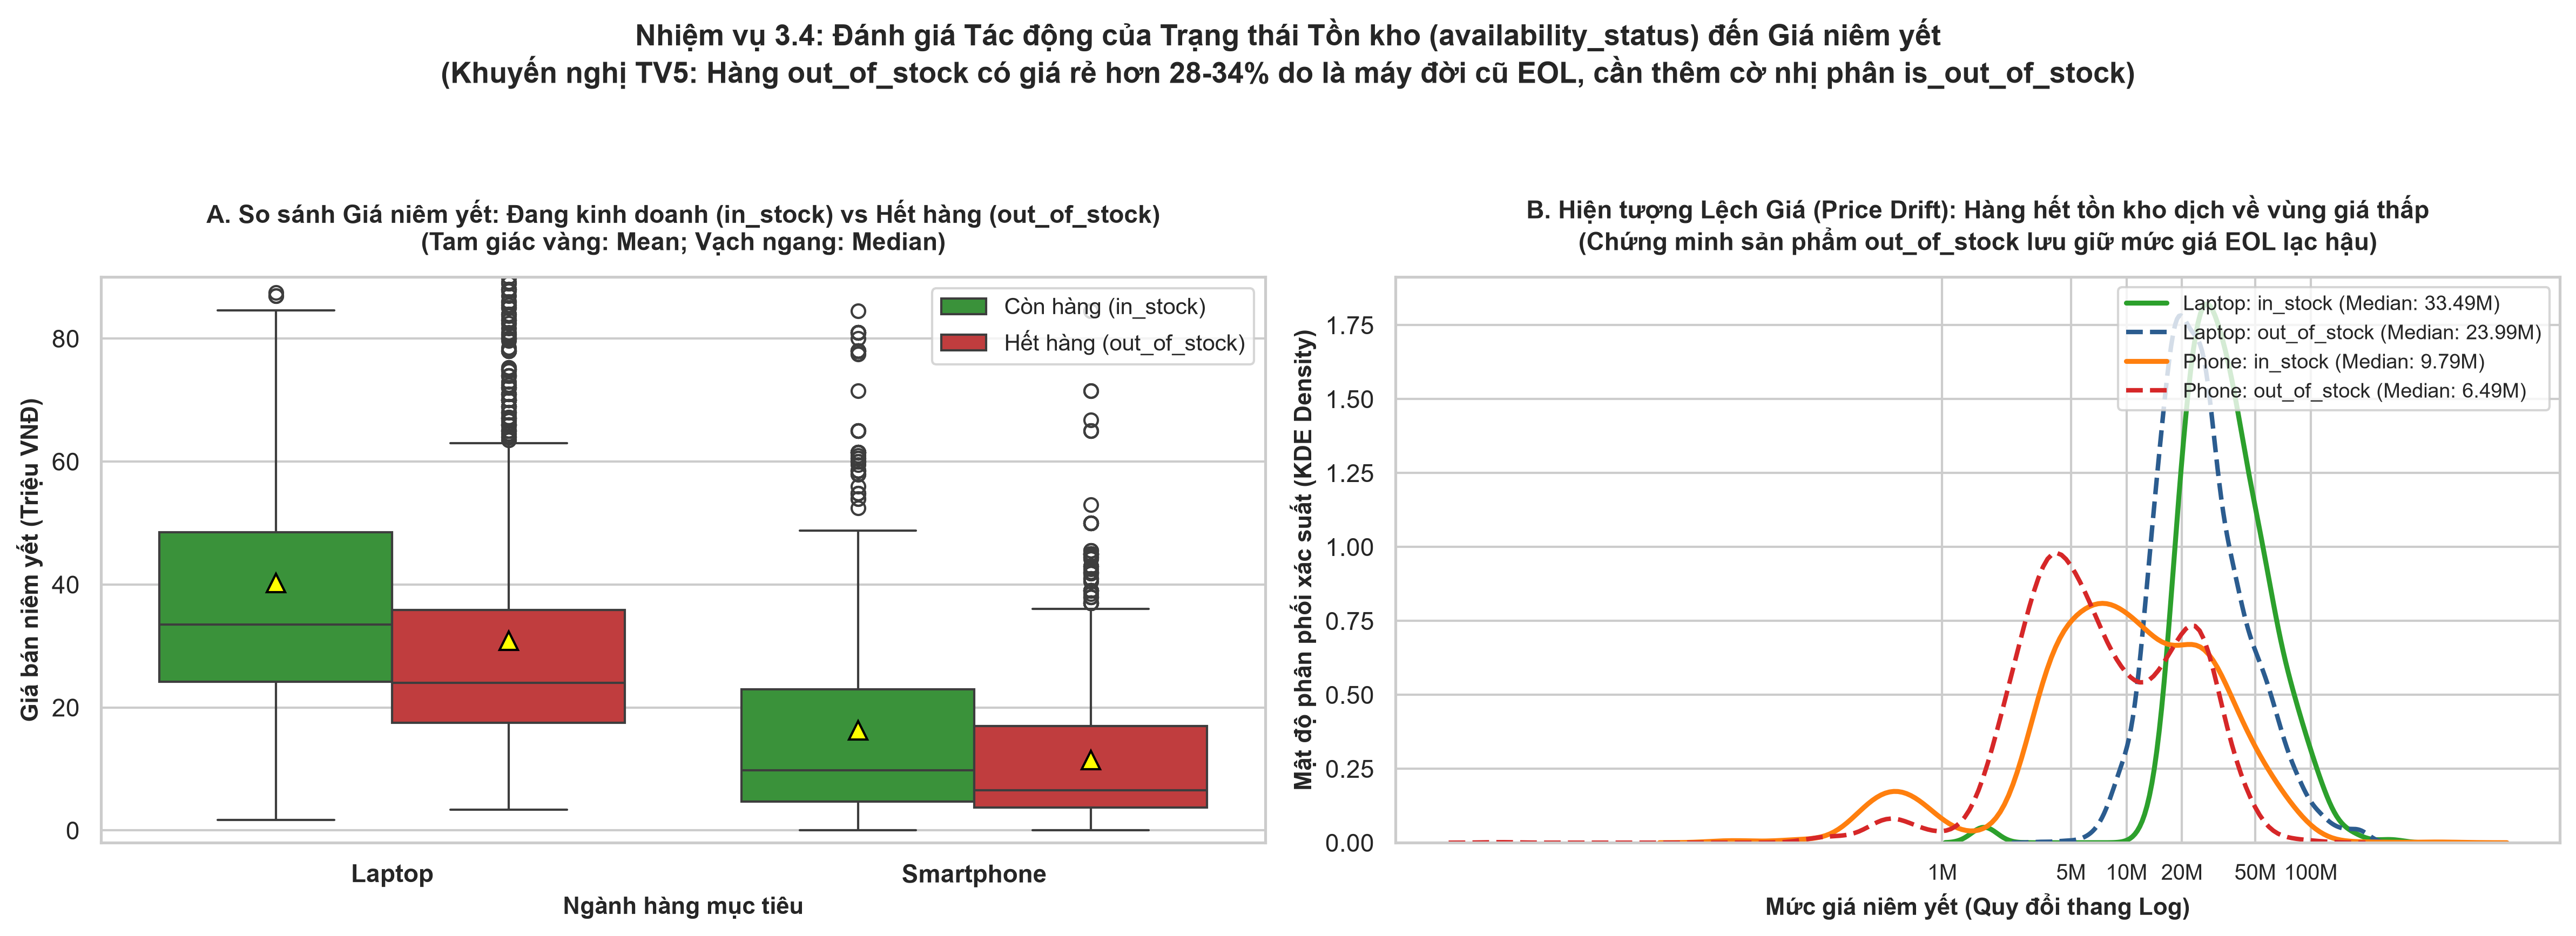

In [9]:
plot_availability_price_comparison(df, "src/eda/outputs/figures/fig_3_3_availability_price_comparison.png")
Image("src/eda/outputs/figures/fig_3_3_availability_price_comparison.png")
